# Project 12: Understanding Convolution and Pooling


**NAME:** **Prakruthi BR**

**REG NO:** **2411021240038**

**SUBJECT:** **Deep Learning**

## Aim
To understand convolution and pooling operations in image processing using Python and visualize how these operations extract important features from images.

## Objectives
1. Load a sample image using Python.
2. Apply different convolution filters to the image.
3. Perform max pooling and average pooling.
4. Visualize and compare the original image, filtered images, and pooled images.
5. Understand how Convolutional Neural Networks (CNNs) extract useful image features.

## Introduction
Convolution and pooling are important operations used in Convolutional Neural Networks (CNNs). CNNs are deep learning models commonly used for image classification, object detection, and image recognition.

Convolution applies a small matrix called a kernel or filter to an image to identify features such as edges, lines, textures, and patterns. Different filters produce different feature maps.

Pooling reduces the spatial dimensions of an image or feature map while retaining important information. It helps reduce computational complexity and can make a model less sensitive to small changes in image position.

## Theory

### 1. Convolution
Convolution involves sliding a filter over an image and calculating weighted sums of the pixel values covered by the filter.

Common filters include:
- **Edge detection filter:** Highlights boundaries and edges.
- **Sharpening filter:** Enhances details and edges.
- **Blur filter:** Smooths the image and reduces fine details.

The output of applying a convolution filter is called a feature map.

### 2. Pooling
Pooling reduces the width and height of a feature map.

- **Max pooling:** Selects the maximum value from each local region.
- **Average pooling:** Calculates the average value of each local region.

For example, given a 2 × 2 region:

[1  3]  
[2  4]

Max pooling produces 4, while average pooling produces 2.5.

## Applications
- Image classification
- Face recognition
- Object detection
- Medical image analysis
- Autonomous vehicles
- Industrial defect detection

## Software and Libraries Required
- Python
- Google Colab or Jupyter Notebook
- NumPy
- Matplotlib
- SciPy
- scikit-image

### Task 1: Loading a Sample Image

In this task, a sample image was loaded using Python's scikit-image library. The original image was displayed in RGB format and then converted into grayscale.

A grayscale image contains intensity values rather than three separate color channels. This simplifies the application of convolution filters and makes it easier to visualize the features extracted from the image.

**Observation:** The original image contains color information, whereas the grayscale image represents brightness variations. The grayscale image is used in the following convolution and pooling experiments.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, color, img_as_float
from scipy.ndimage import convolve

print("Libraries imported successfully!")

Libraries imported successfully!


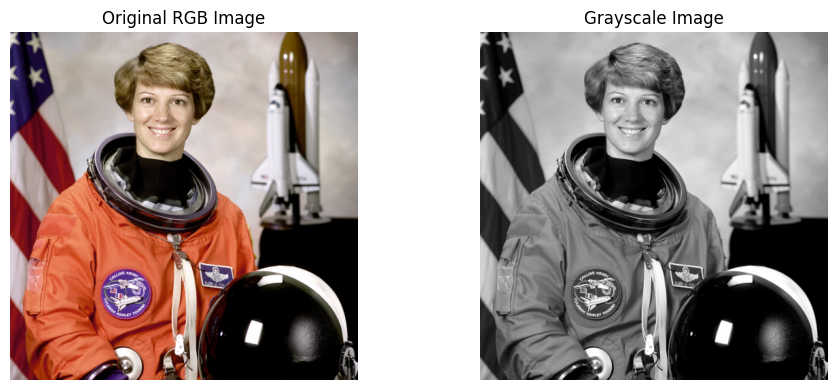

Original image shape: (512, 512, 3)
Grayscale image shape: (512, 512)


In [18]:
# Load a sample image
original_image = data.astronaut()

# Convert the image to floating-point values
original_image = img_as_float(original_image)

# Convert the RGB image to grayscale
gray_image = color.rgb2gray(original_image)

# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original image shape:", original_image.shape)
print("Grayscale image shape:", gray_image.shape)

### Task 2: Applying Convolution Filters and Pooling Operations

In this task, three convolution filters were applied to the grayscale image: edge detection, sharpening, and blurring.

The edge detection filter highlighted changes in pixel intensity, making object boundaries more visible. The sharpening filter enhanced details and edges, while the blur filter smoothed the image.

Max pooling and average pooling were then applied using a 2 × 2 window and a stride of 2. Max pooling retained the maximum value in each window, whereas average pooling calculated the average value.

**Observation:** Convolution filters produced different visual effects depending on the kernel used. Pooling reduced the image dimensions and summarized local pixel information.

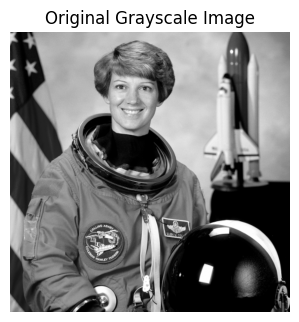

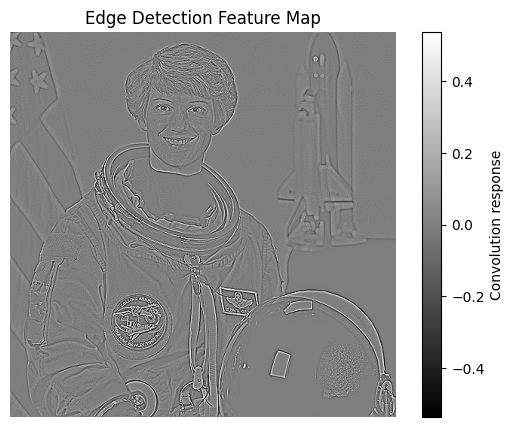

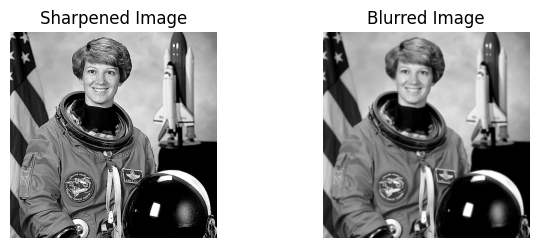

In [19]:
# Define the convolution kernels

# 1. Laplacian edge detection filter
edge_kernel = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
], dtype=float)

# 2. Sharpening filter
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=float)

# 3. Blur filter (averaging filter)
blur_kernel = np.ones((3, 3), dtype=float) / 9

# Apply convolution
edge_image = convolve(gray_image, edge_kernel)
sharpen_image = convolve(gray_image, sharpen_kernel)
blur_image = convolve(gray_image, blur_kernel)

# Display the results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

# Improve the visibility of positive and negative edge responses

edge_limit = np.percentile(np.abs(edge_image), 99)

plt.figure(figsize=(7, 5))

plt.imshow(
    edge_image,
    cmap="gray",
    vmin=-edge_limit,
    vmax=edge_limit
)

plt.title("Edge Detection Feature Map")
plt.axis("off")
plt.colorbar(label="Convolution response")
plt.show()

plt.subplot(2, 2, 3)
plt.imshow(sharpen_image, cmap="gray", vmin=0, vmax=1)
plt.title("Sharpened Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(blur_image, cmap="gray")
plt.title("Blurred Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
def max_pooling(image, pool_size=2):
    height, width = image.shape

    # Use complete pooling windows only
    height = (height // pool_size) * pool_size
    width = (width // pool_size) * pool_size

    cropped = image[:height, :width]

    # Split into non-overlapping pooling windows
    blocks = cropped.reshape(
        height // pool_size, pool_size,
        width // pool_size, pool_size
    )

    return blocks.max(axis=(1, 3))


def average_pooling(image, pool_size=2):
    height, width = image.shape

    height = (height // pool_size) * pool_size
    width = (width // pool_size) * pool_size

    cropped = image[:height, :width]

    blocks = cropped.reshape(
        height // pool_size, pool_size,
        width // pool_size, pool_size
    )

    return blocks.mean(axis=(1, 3))


# Apply pooling to the grayscale image
max_pooled_image = max_pooling(gray_image, pool_size=2)
avg_pooled_image = average_pooling(gray_image, pool_size=2)

print("Original image shape:", gray_image.shape)
print("Max-pooled image shape:", max_pooled_image.shape)
print("Average-pooled image shape:", avg_pooled_image.shape)

Original image shape: (512, 512)
Max-pooled image shape: (256, 256)
Average-pooled image shape: (256, 256)


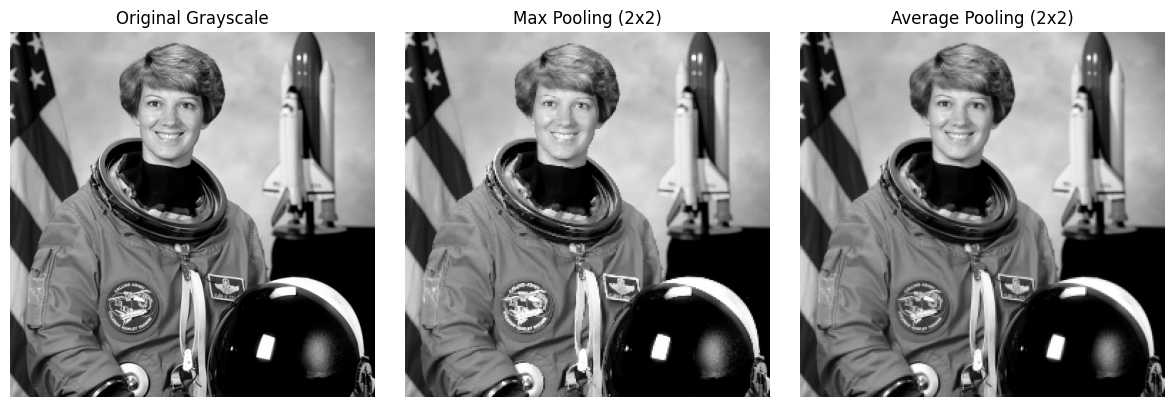

In [21]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(max_pooled_image, cmap="gray")
plt.title("Max Pooling (2x2)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(avg_pooled_image, cmap="gray")
plt.title("Average Pooling (2x2)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Task 3: Visualizing and Comparing Feature Maps

In this task, the original grayscale image was compared with the edge feature map, sharpened image, blurred image, max-pooled image, and average-pooled image.

The edge feature map highlighted intensity changes and object boundaries. The sharpened image emphasized details, while the blurred image reduced fine variations. Max pooling preserved the highest local pixel values, whereas average pooling represented each local region by its mean value.

The dimensions of the original image and the processed images were also compared to understand the effect of pooling.

**Observation:** Convolution helps reveal different image features, while pooling reduces spatial dimensions and summarizes local information. These operations form an important part of CNN-based image processing.

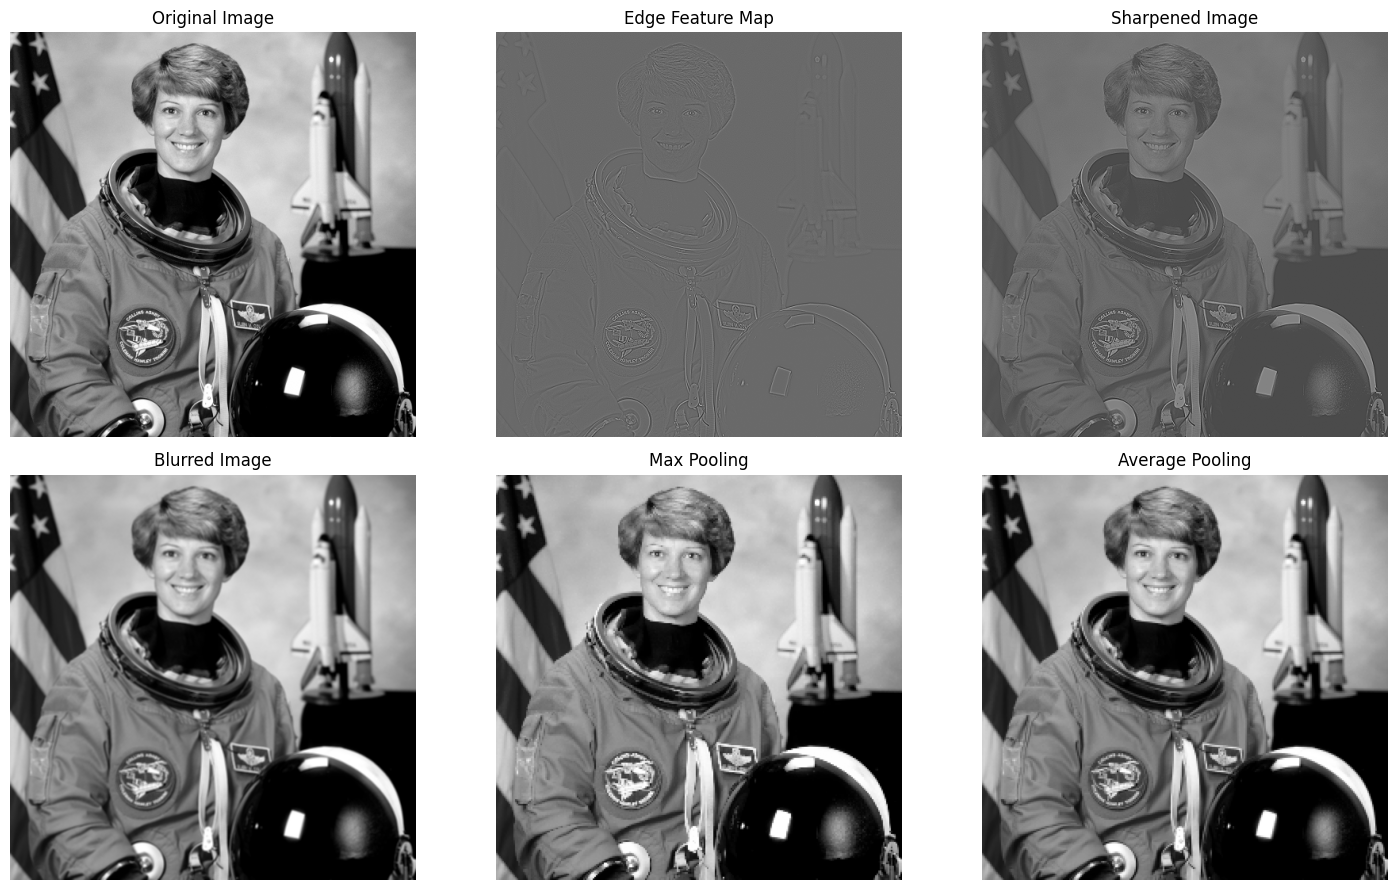

In [22]:
plt.figure(figsize=(15, 9))

images = [
    (gray_image, "Original Image", "gray"),
    (edge_image, "Edge Feature Map", "gray"),
    (sharpen_image, "Sharpened Image", "gray"),
    (blur_image, "Blurred Image", "gray"),
    (max_pooled_image, "Max Pooling", "gray"),
    (avg_pooled_image, "Average Pooling", "gray")
]

for i, (image, title, cmap) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
print("IMAGE DIMENSION COMPARISON")
print("-" * 40)

print("Original grayscale:", gray_image.shape)
print("Edge feature map:   ", edge_image.shape)
print("Sharpened image:    ", sharpen_image.shape)
print("Blurred image:      ", blur_image.shape)
print("Max-pooled image:   ", max_pooled_image.shape)
print("Average-pooled image:", avg_pooled_image.shape)

IMAGE DIMENSION COMPARISON
----------------------------------------
Original grayscale: (512, 512)
Edge feature map:    (512, 512)
Sharpened image:     (512, 512)
Blurred image:       (512, 512)
Max-pooled image:    (256, 256)
Average-pooled image: (256, 256)


## Conclusion

The experiment successfully demonstrated convolution and pooling operations using Python. A sample image was loaded and converted into grayscale. Different convolution filters were applied to identify edges, sharpen details, and smooth the image.

Max pooling and average pooling were used to reduce the spatial dimensions of the image. The processed images and feature maps were visualized and compared with the original image.

Thus, the experiment demonstrated how convolution extracts useful visual patterns and how pooling reduces spatial dimensions. These operations are fundamental components of Convolutional Neural Networks (CNNs), which are widely used in image classification, object detection, and image recognition.

## Result

Convolution and pooling operations were successfully implemented using Python. The original image, convolution-filter outputs, and pooled images were displayed and compared. The experiment demonstrated the effects of edge detection, sharpening, blurring, max pooling, and average pooling on image features and dimensions.